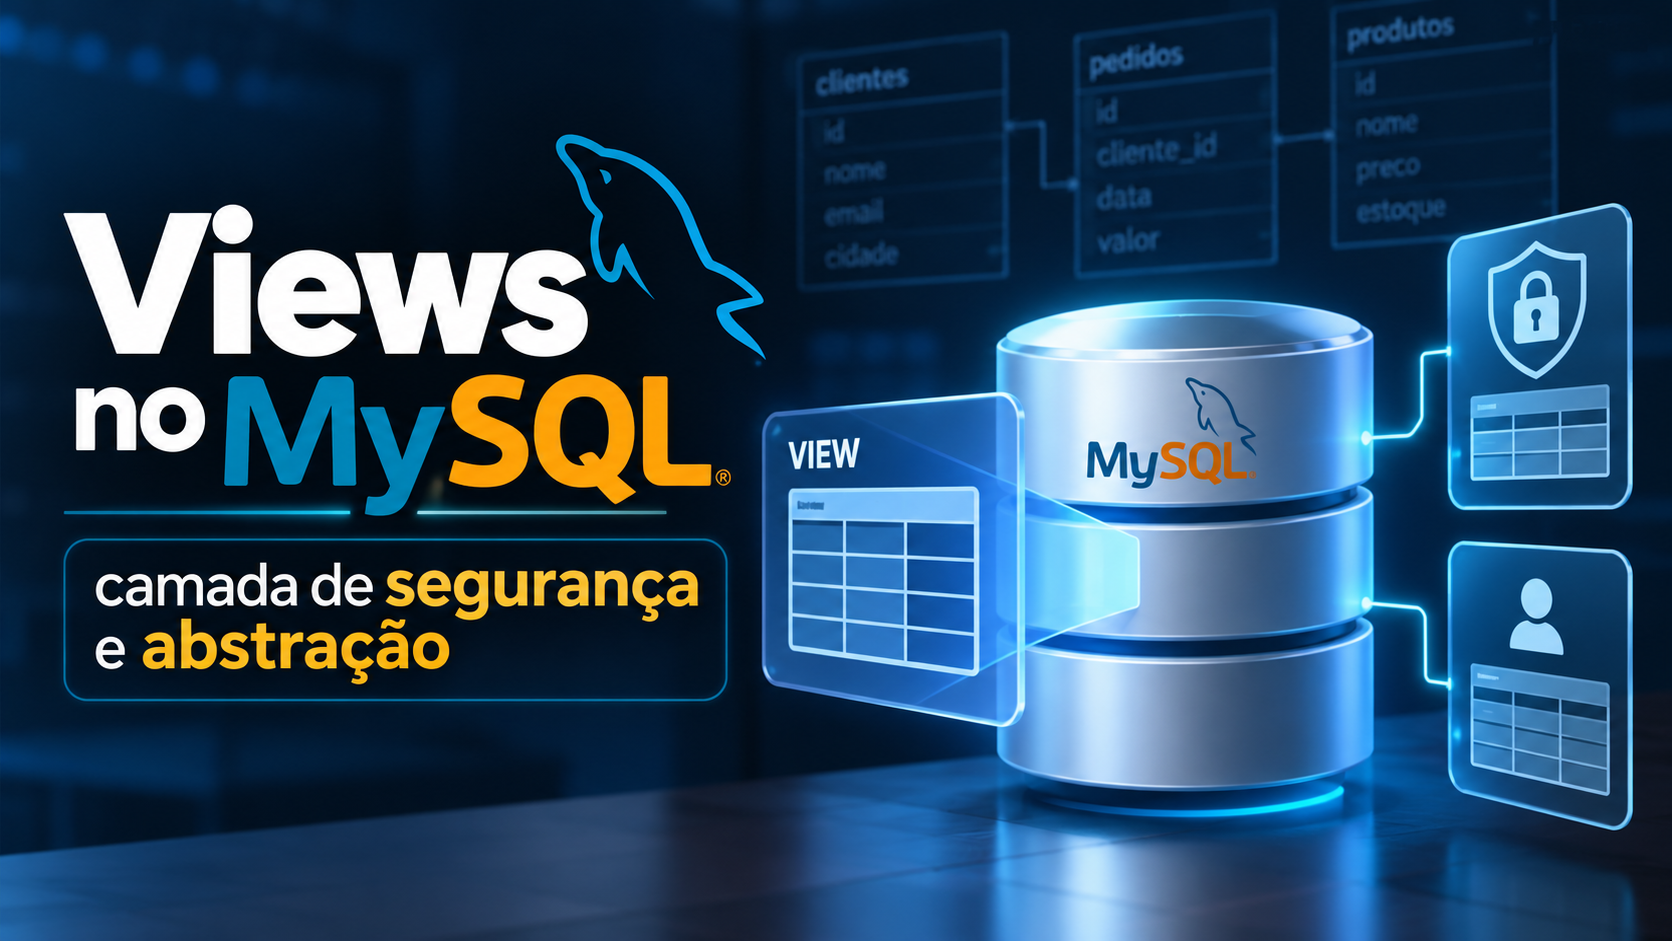

Nas aulas anteriores aprendemos a criar bancos e tabelas, a automatizar regras com **procedures, functions e triggers** e a controlar o acesso com **GRANT e REVOKE**.

Na aula 12 vimos que é possível liberar colunas específicas para um usuário (`GRANT SELECT (nome, email) ON ...`). Isso funciona, mas tem limites: não dá para esconder **linhas**, não dá para **mascarar** um dado e não dá para entregar um **resultado já calculado**.

Nesta aula vamos conhecer as **Views**, uma das ferramentas mais usadas no dia a dia para resolver exatamente esses problemas.

## O que é uma View?

Uma **View** (visão) é uma **consulta `SELECT` salva no banco de dados com um nome**.

Depois de criada, ela pode ser consultada como se fosse uma tabela:

```sql
SELECT * FROM nome_da_view;
```

Mas atenção: **a view não guarda dados**. Cada vez que você consulta a view, o MySQL executa o `SELECT` que está por trás dela e busca os dados nas tabelas originais. Por isso dizemos que a view é uma **tabela virtual**.

| | Tabela | View |
|---|---|---|
| Guarda dados? | Sim | Não, guarda apenas a consulta |
| Ocupa espaço com registros? | Sim | Não |
| Fica atualizada sozinha? | É a própria fonte | Sim, sempre reflete as tabelas |
| Pode receber `GRANT`? | Sim | Sim |

### Para que servem as views?

- **Segurança**: mostrar só algumas colunas ou linhas de uma tabela
- **Abstração**: esconder um `JOIN` complicado atrás de um nome simples
- **Padronização**: todos usam o mesmo cálculo (exemplo: média salarial por departamento)
- **Proteção contra mudanças**: se a tabela mudar, ajustamos só a view e os sistemas continuam funcionando

### Sintaxe básica

```sql
CREATE VIEW nome_da_view AS
SELECT colunas
FROM tabela
WHERE condicao;
```

## Preparando o ambiente

Vamos começar como nas aulas anteriores: importar as bibliotecas, conectar como `root` e criar o banco de dados que usaremos durante a aula.

#### Passo 1: Importar as bibliotecas

In [1]:
import pymysql
import pandas as pd

#### Passo 2: Conectar ao MySQL como administrador

**O que faremos agora:** abrir uma conexão com o usuário `root`. Ele é o administrador e será o responsável por criar as tabelas, as views e os usuários.

In [2]:
conn = pymysql.connect(host="localhost", user="root", password="root")
cursor = conn.cursor()

#### Passo 3: Criar o banco de dados

In [3]:
cursor.execute("DROP DATABASE IF EXISTS sistema_empresa")
cursor.execute("CREATE DATABASE sistema_empresa")
cursor.execute("USE sistema_empresa")

0

#### Passo 4: Criar a tabela `departamentos`

**O que faremos agora:** criar a tabela de departamentos. Cada departamento tem um nome e um orçamento anual.

In [4]:
cursor.execute("""
CREATE TABLE departamentos (
    id INT AUTO_INCREMENT PRIMARY KEY,
    nome VARCHAR(50) NOT NULL,
    orcamento DECIMAL(12,2)
)
""")

0

#### Passo 5: Criar a tabela `funcionarios`

**O que faremos agora:** criar a tabela de funcionários. Repare que ela tem **dados sensíveis**: `cpf` e `salario`. Esses são os dados que vamos proteger com as views.

A coluna `departamento_id` é uma **chave estrangeira** que liga o funcionário ao seu departamento.

In [5]:
cursor.execute("""
CREATE TABLE funcionarios (
    id INT AUTO_INCREMENT PRIMARY KEY,
    nome VARCHAR(100) NOT NULL,
    email VARCHAR(100),
    cpf CHAR(11),
    cargo VARCHAR(50),
    salario DECIMAL(10,2),
    data_admissao DATE,
    departamento_id INT,
    FOREIGN KEY (departamento_id) REFERENCES departamentos(id)
)
""")

0

#### Passo 6: Criar a tabela `projetos`

**O que faremos agora:** criar a tabela de projetos. Cada projeto pertence a um departamento e tem um orçamento e um status.

In [6]:
cursor.execute("""
CREATE TABLE projetos (
    id INT AUTO_INCREMENT PRIMARY KEY,
    nome VARCHAR(100) NOT NULL,
    orcamento DECIMAL(12,2),
    status VARCHAR(20),
    departamento_id INT,
    FOREIGN KEY (departamento_id) REFERENCES departamentos(id)
)
""")

0

#### Passo 7: Inserir os departamentos

**O que faremos agora:** cadastrar três departamentos. Usamos `executemany` para inserir várias linhas com um único comando.

In [7]:
departamentos = [
    ("TI", 500000.00),
    ("RH", 200000.00),
    ("Administrativo", 300000.00)
]

cursor.executemany("INSERT INTO departamentos (nome, orcamento) VALUES (%s, %s)",departamentos)

3

#### Passo 8: Inserir os funcionários

**O que faremos agora:** cadastrar os funcionários. Os quatro primeiros são os mesmos da aula 12; adicionamos mais alguns para que os resultados agrupados fiquem mais interessantes.

Lembre-se: `departamento_id` 1 = TI, 2 = RH, 3 = Administrativo.

In [8]:
funcionarios = [
    ("João Silva",     "joao.silva@empresa.com",     "12345678901", "Desenvolvedor",  8500.00, "2020-03-15", 1),
    ("Maria Santos",   "maria.santos@empresa.com",   "23456789012", "Analista de RH", 6200.00, "2019-07-01", 2),
    ("Pedro Oliveira", "pedro.oliveira@empresa.com", "34567890123", "Gerente",       12000.00, "2018-01-10", 3),
    ("Ana Costa",      "ana.costa@empresa.com",      "45678901234", "Desenvolvedora", 9100.00, "2021-05-20", 1),
    ("Lucas Pereira",  "lucas.pereira@empresa.com",  "56789012345", "Suporte",        4300.00, "2022-02-01", 1),
    ("Carla Mendes",   "carla.mendes@empresa.com",   "67890123456", "Recrutadora",    5100.00, "2021-09-13", 2),
]

cursor.executemany(
    """INSERT INTO funcionarios
       (nome, email, cpf, cargo, salario, data_admissao, departamento_id)
       VALUES (%s, %s, %s, %s, %s, %s, %s)""",
    funcionarios
)

6

#### Passo 9: Inserir os projetos

**O que faremos agora:** cadastrar os projetos da empresa.

In [9]:
projetos = [
    ("Sistema ERP",         250000.00, "Em andamento", 1),
    ("Site Corporativo",     40000.00, "Concluído",    1),
    ("App Mobile",          120000.00, "Em andamento", 1),
    ("Programa de Trainee",  30000.00, "Planejado",    2),
]

cursor.executemany(
    "INSERT INTO projetos (nome, orcamento, status, departamento_id) VALUES (%s, %s, %s, %s)", projetos)

conn.commit()

#### Passo 10: Conferir a tabela `funcionarios`

**O que faremos agora:** olhar a tabela completa. Para exibir o resultado em forma de tabela, usamos o mesmo padrão das aulas anteriores:

- `cursor.fetchall()` traz todas as linhas do resultado
- `cursor.description` guarda os nomes das colunas, que usamos como cabeçalho do DataFrame

Repare que **qualquer pessoa** com acesso a essa tabela consegue ver CPF e salário de todos. Esse é o problema que vamos resolver.

In [10]:
cursor.execute("SELECT * FROM funcionarios")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,id,nome,email,cpf,cargo,salario,data_admissao,departamento_id
0,1,João Silva,joao.silva@empresa.com,12345678901,Desenvolvedor,8500.00,2020-03-15,1
1,2,Maria Santos,maria.santos@empresa.com,23456789012,Analista de RH,6200.00,2019-07-01,2
2,3,Pedro Oliveira,pedro.oliveira@empresa.com,34567890123,Gerente,12000.00,2018-01-10,3
3,4,Ana Costa,ana.costa@empresa.com,45678901234,Desenvolvedora,9100.00,2021-05-20,1
4,5,Lucas Pereira,lucas.pereira@empresa.com,56789012345,Suporte,4300.00,2022-02-01,1
5,6,Carla Mendes,carla.mendes@empresa.com,67890123456,Recrutadora,5100.00,2021-09-13,2


## Parte 1: Criando a primeira View

Imagine que o time de comunicação precisa de uma lista de funcionários para montar o organograma da empresa. Eles precisam de **nome, cargo e e-mail**, mas **não** devem ver CPF nem salário.

Em vez de dar acesso à tabela inteira, vamos criar uma view só com as colunas necessárias.

#### Passo 11: Escrever o SELECT que a view vai guardar

**O que faremos agora:** antes de criar uma view, é uma boa prática **testar a consulta** sozinha. Se o `SELECT` funcionar, a view também vai funcionar.

In [11]:
cursor.execute("SELECT id, nome, cargo, email FROM funcionarios")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,id,nome,cargo,email
0,1,João Silva,Desenvolvedor,joao.silva@empresa.com
1,2,Maria Santos,Analista de RH,maria.santos@empresa.com
2,3,Pedro Oliveira,Gerente,pedro.oliveira@empresa.com
3,4,Ana Costa,Desenvolvedora,ana.costa@empresa.com
4,5,Lucas Pereira,Suporte,lucas.pereira@empresa.com
5,6,Carla Mendes,Recrutadora,carla.mendes@empresa.com


#### Passo 12: Transformar o SELECT em uma View

**O que faremos agora:** basta colocar `CREATE VIEW nome AS` na frente da consulta que acabamos de testar.

Por convenção, vamos usar o prefixo `vw_` no nome das views. Assim fica fácil diferenciar uma view de uma tabela.

In [12]:
cursor.execute("CREATE VIEW vw_funcionarios_publico AS SELECT id, nome, cargo, email FROM funcionarios")

0

#### Passo 13: Consultar a View

**O que faremos agora:** consultar a view exatamente como consultamos uma tabela. Note que **não aparecem** as colunas `cpf` e `salario`.

In [13]:
cursor.execute("SELECT * FROM vw_funcionarios_publico")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,id,nome,cargo,email
0,1,João Silva,Desenvolvedor,joao.silva@empresa.com
1,2,Maria Santos,Analista de RH,maria.santos@empresa.com
2,3,Pedro Oliveira,Gerente,pedro.oliveira@empresa.com
3,4,Ana Costa,Desenvolvedora,ana.costa@empresa.com
4,5,Lucas Pereira,Suporte,lucas.pereira@empresa.com
5,6,Carla Mendes,Recrutadora,carla.mendes@empresa.com


#### Passo 14: Usar WHERE e ORDER BY na View

**O que faremos agora:** mostrar que a view aceita os mesmos recursos de uma tabela. Vamos filtrar só os desenvolvedores e ordenar por nome.

In [14]:
cursor.execute("SELECT nome, cargo FROM vw_funcionarios_publico WHERE cargo LIKE 'Desenvolvedor%' ORDER BY nome")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,nome,cargo
0,Ana Costa,Desenvolvedora
1,João Silva,Desenvolvedor


#### Passo 15: Provar que a View não guarda dados

**O que faremos agora:** vamos alterar o cargo do Lucas **na tabela original** e depois consultar a **view**. Se a view guardasse uma cópia dos dados, a mudança não apareceria.

In [15]:
cursor.execute("UPDATE funcionarios SET cargo = 'Analista de Suporte' WHERE nome = 'Lucas Pereira'")
conn.commit()

In [16]:
cursor.execute("SELECT * FROM vw_funcionarios_publico WHERE nome = 'Lucas Pereira'")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,id,nome,cargo,email
0,5,Lucas Pereira,Analista de Suporte,lucas.pereira@empresa.com


> A view mostrou o cargo novo imediatamente. Isso confirma que ela **executa a consulta toda vez** que é chamada, buscando os dados direto da tabela `funcionarios`.

## Parte 2: Onde as Views ficam guardadas?

As views são objetos do banco, assim como as tabelas. Vamos aprender a listá-las e ver como foram criadas.

#### Passo 17: Listar tabelas e views juntas

**O que faremos agora:** o comando `SHOW FULL TABLES` lista tudo o que existe no banco e informa o tipo de cada objeto na coluna `Table_type`:

- `BASE TABLE` = tabela de verdade
- `VIEW` = view

In [17]:
cursor.execute("SHOW FULL TABLES")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,Tables_in_sistema_empresa,Table_type
0,departamentos,BASE TABLE
1,funcionarios,BASE TABLE
2,projetos,BASE TABLE
3,vw_funcionarios_publico,VIEW


#### Passo 18: Listar somente as views

**O que faremos agora:** filtrar o resultado para mostrar apenas os objetos do tipo `VIEW`.

In [18]:
cursor.execute("SHOW FULL TABLES WHERE Table_type = 'VIEW'")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,Tables_in_sistema_empresa,Table_type
0,vw_funcionarios_publico,VIEW


#### Passo 19: Ver o código de uma View

**O que faremos agora:** o comando `SHOW CREATE VIEW` mostra o SQL completo que o MySQL guardou para a view. Isso é útil quando você encontra uma view criada por outra pessoa e quer entender o que ela faz.

In [19]:
cursor.execute("SHOW CREATE VIEW vw_funcionarios_publico")
resultado = cursor.fetchone()
print(resultado[1])

CREATE ALGORITHM=UNDEFINED DEFINER=`root`@`localhost` SQL SECURITY DEFINER VIEW `vw_funcionarios_publico` AS select `funcionarios`.`id` AS `id`,`funcionarios`.`nome` AS `nome`,`funcionarios`.`cargo` AS `cargo`,`funcionarios`.`email` AS `email` from `funcionarios`


> Repare em dois detalhes que o MySQL acrescentou sozinho:
> - `DEFINER=root@localhost`: quem criou a view
> - `SQL SECURITY DEFINER`: a view roda **com as permissões de quem a criou**. Vamos ver por que isso é tão importante na parte de segurança.

#### Passo 20: Consultar o dicionário de dados

**O que faremos agora:** o MySQL guarda informações sobre todas as views na tabela `information_schema.VIEWS`. Vamos consultar algumas colunas dela.

In [20]:
cursor.execute("""
SELECT TABLE_NAME, DEFINER, SECURITY_TYPE, IS_UPDATABLE
FROM information_schema.VIEWS
WHERE TABLE_SCHEMA = 'sistema_empresa'
""")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,TABLE_NAME,DEFINER,SECURITY_TYPE,IS_UPDATABLE
0,vw_funcionarios_publico,root@localhost,DEFINER,YES


## Parte 3: Views para simplificar consultas (abstração)

Agora vamos usar views para **esconder a complexidade**. Uma consulta com `JOIN` pode ser difícil para quem está começando ou para um analista que só quer gerar um relatório. Com uma view, essa pessoa só precisa saber o nome da view.

#### Passo 21: Lembrando o problema

**O que faremos agora:** a tabela `funcionarios` só guarda o **número** do departamento (`departamento_id`). Para ver o **nome** do departamento, precisamos de um `JOIN`. Veja primeiro como a tabela aparece sem ele.

In [21]:
cursor.execute("SELECT nome, cargo, departamento_id FROM funcionarios")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,nome,cargo,departamento_id
0,João Silva,Desenvolvedor,1
1,Maria Santos,Analista de RH,2
2,Pedro Oliveira,Gerente,3
3,Ana Costa,Desenvolvedora,1
4,Lucas Pereira,Analista de Suporte,1
5,Carla Mendes,Recrutadora,2


#### Passo 22: Testar a consulta com JOIN

**O que faremos agora:** juntar `funcionarios` com `departamentos` para trazer o nome do departamento. Usamos apelidos (`f` e `d`) para deixar o código mais curto.

In [22]:
cursor.execute("""
SELECT f.nome, f.cargo, d.nome AS departamento
FROM funcionarios f
JOIN departamentos d ON f.departamento_id = d.id
""")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,nome,cargo,departamento
0,João Silva,Desenvolvedor,TI
1,Ana Costa,Desenvolvedora,TI
2,Lucas Pereira,Analista de Suporte,TI
3,Maria Santos,Analista de RH,RH
4,Carla Mendes,Recrutadora,RH
5,Pedro Oliveira,Gerente,Administrativo


#### Passo 23: Guardar o JOIN em uma View

**O que faremos agora:** criar a view `vw_funcionarios_departamento`. Também vamos incluir a data de admissão, mas **sem o salário e sem o CPF**.

In [23]:
cursor.execute("""
CREATE VIEW vw_funcionarios_departamento AS
SELECT f.id,
       f.nome,
       f.cargo,
       d.nome AS departamento,
       f.data_admissao
FROM funcionarios f
JOIN departamentos d ON f.departamento_id = d.id
""")

0

#### Passo 24: Consultar a View com JOIN

**O que faremos agora:** quem usar essa view não precisa saber nada de `JOIN`. É só um `SELECT` simples.

In [24]:
cursor.execute("SELECT * FROM vw_funcionarios_departamento")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,id,nome,cargo,departamento,data_admissao
0,1,João Silva,Desenvolvedor,TI,2020-03-15
1,4,Ana Costa,Desenvolvedora,TI,2021-05-20
2,5,Lucas Pereira,Analista de Suporte,TI,2022-02-01
3,2,Maria Santos,Analista de RH,RH,2019-07-01
4,6,Carla Mendes,Recrutadora,RH,2021-09-13
5,3,Pedro Oliveira,Gerente,Administrativo,2018-01-10


#### Passo 25: Filtrar pela coluna que veio do JOIN

**O que faremos agora:** filtrar pelos funcionários de TI usando o **nome** do departamento, algo que não era possível direto na tabela `funcionarios`.

In [25]:
cursor.execute("SELECT nome, cargo FROM vw_funcionarios_departamento WHERE departamento = 'TI'")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,nome,cargo
0,João Silva,Desenvolvedor
1,Ana Costa,Desenvolvedora
2,Lucas Pereira,Analista de Suporte


#### Passo 26: Testar uma consulta com agregação

**O que faremos agora:** a diretoria quer um resumo por departamento: **quantidade de funcionários**, **média salarial** e **soma da folha de pagamento**. Ela **não** quer (e não deve) ver o salário de cada pessoa individualmente.

Vamos testar a consulta com `COUNT`, `AVG`, `SUM` e `GROUP BY`.

In [26]:
cursor.execute("""
SELECT d.nome AS departamento,
       COUNT(f.id) AS qtd_funcionarios,
       ROUND(AVG(f.salario), 2) AS media_salarial,
       SUM(f.salario) AS folha_total
FROM departamentos d
JOIN funcionarios f ON f.departamento_id = d.id
GROUP BY d.nome
""")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,departamento,qtd_funcionarios,media_salarial,folha_total
0,TI,3,7300.00,21900.00
1,RH,2,5650.00,11300.00
2,Administrativo,1,12000.00,12000.00


#### Passo 27: Criar a View de resumo

**O que faremos agora:** guardar essa consulta como a view `vw_resumo_departamentos`.

Isso também resolve um problema de **padronização**: se cada analista escrevesse a própria consulta, alguém poderia esquecer o `ROUND` ou calcular a média de outro jeito. Com a view, todos usam o mesmo cálculo.

In [27]:
cursor.execute("""
CREATE VIEW vw_resumo_departamentos AS
SELECT d.nome AS departamento,
       COUNT(f.id) AS qtd_funcionarios,
       ROUND(AVG(f.salario), 2) AS media_salarial,
       SUM(f.salario) AS folha_total
FROM departamentos d
JOIN funcionarios f ON f.departamento_id = d.id
GROUP BY d.nome
""")

0

#### Passo 28: Consultar a View de resumo

**O que faremos agora:** consultar a view ordenando pela folha de pagamento, do maior para o menor.

In [28]:
cursor.execute("SELECT * FROM vw_resumo_departamentos ORDER BY folha_total DESC")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,departamento,qtd_funcionarios,media_salarial,folha_total
0,TI,3,7300.00,21900.00
1,Administrativo,1,12000.00,12000.00
2,RH,2,5650.00,11300.00


#### Passo 29: Uma View que usa outra View

**O que faremos agora:** uma view pode ser construída em cima de outra view. Vamos criar `vw_departamentos_acima_media`, que mostra apenas os departamentos com média salarial acima de R$ 7.000, usando a view do passo anterior.

In [29]:
cursor.execute("""
CREATE VIEW vw_departamentos_acima_media AS
SELECT departamento, media_salarial
FROM vw_resumo_departamentos
WHERE media_salarial > 7000
""")

0

In [30]:
cursor.execute("SELECT * FROM vw_departamentos_acima_media")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,departamento,media_salarial
0,TI,7300.00
1,Administrativo,12000.00


> **Cuidado:** empilhar muitas views (view de view de view) deixa o sistema difícil de entender e pode deixar as consultas mais lentas. Use com moderação.

## Parte 4: Mascaramento de dados

Às vezes um usuário precisa **saber que o dado existe**, mas não precisa vê-lo inteiro. Um exemplo comum é o atendimento: o atendente confirma "seu e-mail é jo\*\*\*@empresa.com?" sem enxergar o endereço completo.

O `GRANT` por coluna (aula 12) **não consegue fazer isso**: ou o usuário vê a coluna inteira, ou não vê nada. Com uma view, podemos **transformar** o dado antes de entregá-lo.

#### Passo 30: Conhecer as funções de texto que vamos usar

**O que faremos agora:** testar as funções que vão montar a máscara:

- `LEFT(texto, n)`: pega os `n` primeiros caracteres
- `RIGHT(texto, n)`: pega os `n` últimos caracteres
- `LOCATE('@', texto)`: diz em qual posição está o `@`
- `SUBSTRING(texto, posicao)`: pega o texto a partir de uma posição
- `CONCAT(...)`: junta vários textos

In [31]:
cursor.execute("""
SELECT email,
       LEFT(email, 2)                      AS dois_primeiros,
       LOCATE('@', email)                  AS posicao_arroba,
       SUBSTRING(email, LOCATE('@', email)) AS dominio
FROM funcionarios
LIMIT 2
""")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,email,dois_primeiros,posicao_arroba,dominio
0,joao.silva@empresa.com,jo,11,@empresa.com
1,maria.santos@empresa.com,ma,13,@empresa.com


#### Passo 31: Montar o e-mail mascarado

**O que faremos agora:** juntar as partes: dois primeiros caracteres + `***` + domínio.

In [32]:
cursor.execute("SELECT email, CONCAT(LEFT(email, 2), '***', SUBSTRING(email, LOCATE('@', email))) AS email_mascarado FROM funcionarios")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,email,email_mascarado
0,joao.silva@empresa.com,jo***@empresa.com
1,maria.santos@empresa.com,ma***@empresa.com
2,pedro.oliveira@empresa.com,pe***@empresa.com
3,ana.costa@empresa.com,an***@empresa.com
4,lucas.pereira@empresa.com,lu***@empresa.com
5,carla.mendes@empresa.com,ca***@empresa.com


#### Passo 32: Montar o CPF mascarado

**O que faremos agora:** fazer o mesmo com o CPF, mostrando apenas os **dois últimos dígitos**. É o formato que muitos sistemas usam: `***.***.***-01`.

In [33]:
cursor.execute("SELECT cpf, CONCAT('***.***.***-', RIGHT(cpf, 2)) AS cpf_mascarado FROM funcionarios")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,cpf,cpf_mascarado
0,12345678901,***.***.***-01
1,23456789012,***.***.***-12
2,34567890123,***.***.***-23
3,45678901234,***.***.***-34
4,56789012345,***.***.***-45
5,67890123456,***.***.***-56


#### Passo 33: Criar a View de atendimento com dados mascarados

**O que faremos agora:** criar a view `vw_funcionarios_atendimento`, que entrega nome, e-mail mascarado e CPF mascarado.

In [34]:
cursor.execute("""
CREATE VIEW vw_funcionarios_atendimento AS
SELECT nome,
       CONCAT(LEFT(email, 2), '***', SUBSTRING(email, LOCATE('@', email))) AS email,
       CONCAT('***.***.***-', RIGHT(cpf, 2)) AS cpf
FROM funcionarios
""")

0

In [35]:
cursor.execute("SELECT * FROM vw_funcionarios_atendimento")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,nome,email,cpf
0,João Silva,jo***@empresa.com,***.***.***-01
1,Maria Santos,ma***@empresa.com,***.***.***-12
2,Pedro Oliveira,pe***@empresa.com,***.***.***-23
3,Ana Costa,an***@empresa.com,***.***.***-34
4,Lucas Pereira,lu***@empresa.com,***.***.***-45
5,Carla Mendes,ca***@empresa.com,***.***.***-56


> Repare que na view as colunas mascaradas continuam com os nomes `email` e `cpf`. Para quem consulta, parece uma tabela normal, mas o dado real nunca sai do banco.

## Parte 5: Alterando e removendo Views

Requisitos mudam. Vamos ver como ajustar uma view que já existe.

#### Passo 34: Tentar criar uma View que já existe

**O que faremos agora:** a equipe pediu para incluir a **data de admissão** na `vw_funcionarios_publico`. Se usarmos `CREATE VIEW` de novo, o MySQL vai reclamar que a view já existe. Vamos ver o erro usando `try/except`.

In [36]:
try:
    cursor.execute("""
    CREATE VIEW vw_funcionarios_publico AS
    SELECT id, nome, cargo, email, data_admissao
    FROM funcionarios
    """)
except pymysql.MySQLError as e:
    print("Erro:", e)

Erro: (1050, "Table 'vw_funcionarios_publico' already exists")


#### Passo 35: Usar CREATE OR REPLACE VIEW

**O que faremos agora:** o comando `CREATE OR REPLACE VIEW` cria a view se ela não existir ou **substitui** a definição se ela já existir. É a forma mais comum de alterar uma view.

> Existe também o comando `ALTER VIEW`, que tem o mesmo efeito, mas só funciona se a view já existir.

In [37]:
cursor.execute("CREATE OR REPLACE VIEW vw_funcionarios_publico AS SELECT id, nome, cargo, email, data_admissao FROM funcionarios")

0

In [38]:
cursor.execute("SELECT * FROM vw_funcionarios_publico")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,id,nome,cargo,email,data_admissao
0,1,João Silva,Desenvolvedor,joao.silva@empresa.com,2020-03-15
1,2,Maria Santos,Analista de RH,maria.santos@empresa.com,2019-07-01
2,3,Pedro Oliveira,Gerente,pedro.oliveira@empresa.com,2018-01-10
3,4,Ana Costa,Desenvolvedora,ana.costa@empresa.com,2021-05-20
4,5,Lucas Pereira,Analista de Suporte,lucas.pereira@empresa.com,2022-02-01
5,6,Carla Mendes,Recrutadora,carla.mendes@empresa.com,2021-09-13


#### Passo 36: Remover uma View

**O que faremos agora:** a view `vw_departamentos_acima_media` não será mais usada. Vamos removê-la com `DROP VIEW IF EXISTS`.

> **Importante:** remover uma view **não apaga nenhum dado**, porque a view não guarda dados. As tabelas continuam intactas.

In [39]:
cursor.execute("DROP VIEW IF EXISTS vw_departamentos_acima_media")

0

In [40]:
cursor.execute("SHOW FULL TABLES WHERE Table_type = 'VIEW'")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,Tables_in_sistema_empresa,Table_type
0,vw_funcionarios_atendimento,VIEW
1,vw_funcionarios_departamento,VIEW
2,vw_funcionarios_publico,VIEW
3,vw_resumo_departamentos,VIEW


## Parte 6: Views atualizáveis e WITH CHECK OPTION

Até aqui só fizemos `SELECT` nas views. Mas em alguns casos é possível fazer `INSERT`, `UPDATE` e `DELETE` **através de uma view**, e a alteração vai parar na tabela original.

Uma view é **atualizável** quando o MySQL consegue saber exatamente qual linha da tabela original corresponde a cada linha da view. Por isso, a view **não** pode ter:

- Funções de agregação (`SUM`, `AVG`, `COUNT`...)
- `GROUP BY` ou `HAVING`
- `DISTINCT`
- `UNION`
- Subconsultas no `SELECT`

#### Passo 37: Verificar quais views são atualizáveis

**O que faremos agora:** consultar de novo a coluna `IS_UPDATABLE` do `information_schema`. Repare que a view de resumo (que tem `GROUP BY`) **não** é atualizável.

In [41]:
cursor.execute("""
SELECT TABLE_NAME, IS_UPDATABLE
FROM information_schema.VIEWS
WHERE TABLE_SCHEMA = 'sistema_empresa'
""")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,TABLE_NAME,IS_UPDATABLE
0,vw_funcionarios_atendimento,YES
1,vw_funcionarios_departamento,YES
2,vw_funcionarios_publico,YES
3,vw_resumo_departamentos,NO


#### Passo 38: Criar uma View para o departamento de TI

**O que faremos agora:** criar a view `vw_funcionarios_ti`, que mostra apenas os funcionários do departamento 1 (TI). Ela é simples, sem agregação, então será atualizável.

In [42]:
cursor.execute("""
CREATE VIEW vw_funcionarios_ti AS
SELECT id, nome, cargo, salario, departamento_id
FROM funcionarios
WHERE departamento_id = 1
""")

0

In [43]:
cursor.execute("SELECT * FROM vw_funcionarios_ti")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,id,nome,cargo,salario,departamento_id
0,1,João Silva,Desenvolvedor,8500.00,1
1,4,Ana Costa,Desenvolvedora,9100.00,1
2,5,Lucas Pereira,Analista de Suporte,4300.00,1


#### Passo 39: Fazer um UPDATE através da View

**O que faremos agora:** dar um aumento para o Lucas **usando a view**. Depois vamos conferir na **tabela original**.

In [44]:
cursor.execute("UPDATE vw_funcionarios_ti SET salario = 4800.00 WHERE nome = 'Lucas Pereira'")
conn.commit()

In [45]:
cursor.execute("SELECT nome, salario FROM funcionarios WHERE nome = 'Lucas Pereira'")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,nome,salario
0,Lucas Pereira,4800.00


> O salário mudou na tabela `funcionarios`. A view funcionou como uma "janela" para a tabela original.

#### Passo 40: Tentar fazer UPDATE em uma View não atualizável

**O que faremos agora:** tentar alterar a `vw_resumo_departamentos`. Como ela tem `GROUP BY` e `AVG`, o MySQL não sabe qual salário mudar e vai recusar.

In [46]:
try:
    cursor.execute("UPDATE vw_resumo_departamentos SET media_salarial = 10000 WHERE departamento = 'TI'")
except pymysql.MySQLError as e:
    print("Erro:", e)

Erro: (1288, 'The target table vw_resumo_departamentos of the UPDATE is not updatable')


#### Passo 41: O problema da linha que "some"

**O que faremos agora:** a view `vw_funcionarios_ti` deveria mostrar só gente de TI. Mas veja o que acontece se, **através dela**, mudarmos o departamento de alguém para RH (`departamento_id = 2`).

In [47]:
cursor.execute("UPDATE vw_funcionarios_ti SET departamento_id = 2 WHERE nome = 'Lucas Pereira'")
conn.commit()

In [48]:
cursor.execute("SELECT * FROM vw_funcionarios_ti")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,id,nome,cargo,salario,departamento_id
0,1,João Silva,Desenvolvedor,8500.00,1
1,4,Ana Costa,Desenvolvedora,9100.00,1


> O Lucas **sumiu** da view! O MySQL aceitou a alteração, mas o registro saiu do filtro `WHERE departamento_id = 1`.
>
> Imagine que essa view fosse usada pelo gerente de TI: ele conseguiria "transferir" funcionários para outros departamentos, mesmo que só devesse enxergar o próprio time. Isso é uma **falha de segurança**.

#### Passo 42: Desfazer a alteração

**O que faremos agora:** devolver o Lucas para o departamento de TI, agora direto na tabela original.

In [49]:
cursor.execute("UPDATE funcionarios SET departamento_id = 1 WHERE nome = 'Lucas Pereira'")
conn.commit()

#### Passo 43: Recriar a View com WITH CHECK OPTION

**O que faremos agora:** a cláusula `WITH CHECK OPTION` diz ao MySQL: **"só aceite `INSERT` ou `UPDATE` se a linha continuar visível na view depois da alteração"**.

Vamos recriar a view com essa proteção.

In [50]:
cursor.execute("""
CREATE OR REPLACE VIEW vw_funcionarios_ti AS
SELECT id, nome, cargo, salario, departamento_id
FROM funcionarios
WHERE departamento_id = 1
WITH CHECK OPTION
""")

0

#### Passo 44: Tentar mover alguém para fora da View

**O que faremos agora:** repetir a mesma alteração do passo 41. Agora o MySQL deve **bloquear**.

In [51]:
try:
    cursor.execute("UPDATE vw_funcionarios_ti SET departamento_id = 2 WHERE nome = 'Lucas Pereira'")
    conn.commit()
except pymysql.MySQLError as e:
    print("Erro:", e)

Erro: (1369, "CHECK OPTION failed 'sistema_empresa.vw_funcionarios_ti'")


#### Passo 45: Tentar inserir alguém de outro departamento pela View

**O que faremos agora:** o `WITH CHECK OPTION` também vale para `INSERT`. Vamos tentar cadastrar uma pessoa do Administrativo (`departamento_id = 3`) usando a view de TI.

In [52]:
try:
    cursor.execute("""
    INSERT INTO vw_funcionarios_ti (nome, cargo, salario, departamento_id)
    VALUES ('Rafael Lima', 'Assistente', 3500.00, 3)
    """)
    conn.commit()
except pymysql.MySQLError as e:
    print("Erro:", e)

Erro: (1369, "CHECK OPTION failed 'sistema_empresa.vw_funcionarios_ti'")


#### Passo 46: Inserir alguém de TI pela View

**O que faremos agora:** agora um cadastro válido, com `departamento_id = 1`. O MySQL deve aceitar.

> As colunas que não estão na view (`email`, `cpf`, `data_admissao`) ficarão como `NULL` na tabela.

In [53]:
cursor.execute("""
INSERT INTO vw_funcionarios_ti (nome, cargo, salario, departamento_id)
VALUES ('Rafael Lima', 'Estagiário de TI', 2000.00, 1)
""")
conn.commit()

In [54]:
cursor.execute("SELECT * FROM funcionarios WHERE nome = 'Rafael Lima'")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,id,nome,email,cpf,cargo,salario,data_admissao,departamento_id
0,7,Rafael Lima,None,None,Estagiário de TI,2000.00,None,1


## Parte 7: Views + GRANT = segurança de verdade

Agora vamos juntar o que aprendemos nesta aula com o que vimos na aula 12.

A ideia é simples:

1. O `root` cria as views
2. Cada usuário recebe `GRANT SELECT` **somente na view** que precisa
3. O usuário **não** recebe nenhuma permissão nas tabelas originais

### Mas como o usuário lê a view sem ter acesso à tabela?

Lembra do `SQL SECURITY DEFINER` que apareceu no `SHOW CREATE VIEW`? Ele significa que a view é executada **com as permissões de quem a criou** (o `root`), e não de quem está consultando.

Então o usuário só precisa de permissão na **view**. A view, por sua vez, "pega emprestada" a permissão do `root` para ler a tabela.

| Usuário | Precisa de | Vai acessar |
|---|---|---|
| `comunicacao` | Lista de funcionários sem dados sensíveis | `vw_funcionarios_publico` |
| `diretoria` | Números agregados por departamento | `vw_resumo_departamentos` |
| `atendente` | Confirmar e-mail e CPF sem ver o dado completo | `vw_funcionarios_atendimento` |

#### Passo 47: Criar os usuários

**O que faremos agora:** criar os três usuários. Assim como na aula 12, primeiro removemos o usuário caso ele já exista.

In [55]:
usuarios = [
    ("comunicacao", "senha_com123"),
    ("diretoria",   "senha_dir123"),
    ("atendente",   "senha_ate123"),
]

for u in usuarios:
    cursor.execute(f"DROP USER IF EXISTS '{u[0]}'@'localhost'")
    cursor.execute(f"CREATE USER '{u[0]}'@'localhost' IDENTIFIED BY '{u[1]}'")

#### Passo 48: Dar permissão ao usuário `comunicacao`

**O que faremos agora:** liberar `SELECT` **apenas** na view `vw_funcionarios_publico`. Repare que o comando é igual ao `GRANT` de uma tabela: para o MySQL, a view é um objeto como outro qualquer.

In [56]:
cursor.execute("GRANT SELECT ON sistema_empresa.vw_funcionarios_publico TO 'comunicacao'@'localhost'")

0

#### Passo 49: Dar permissão ao usuário `diretoria`

**O que faremos agora:** liberar `SELECT` apenas na view de resumo.

In [57]:
cursor.execute("GRANT SELECT ON sistema_empresa.vw_resumo_departamentos TO 'diretoria'@'localhost'")

0

#### Passo 50: Dar permissão ao usuário `atendente`

**O que faremos agora:** liberar `SELECT` apenas na view com dados mascarados.

In [58]:
cursor.execute("GRANT SELECT ON sistema_empresa.vw_funcionarios_atendimento TO 'atendente'@'localhost'")

0

#### Passo 51: Aplicar as permissões

**O que faremos agora:** recarregar as permissões com `FLUSH PRIVILEGES`.

In [59]:
cursor.execute("FLUSH PRIVILEGES")

0

#### Passo 52: Conferir as permissões de cada usuário

**O que faremos agora:** usar `SHOW GRANTS` para confirmar que cada usuário tem acesso **somente** à sua view.

> A linha `GRANT USAGE ON *.*` significa apenas "pode se conectar". Ela não dá acesso a nenhum dado.

In [60]:
for u in usuarios:
    cursor.execute(f"SHOW GRANTS FOR '{u[0]}'@'localhost'")
    print(f"\n\033[1m{u[0]}\033[0m")
    for g in cursor.fetchall():
        print("  ", g[0])


comunicacao
   GRANT USAGE ON *.* TO `comunicacao`@`localhost`
   GRANT SELECT ON `sistema_empresa`.`vw_funcionarios_publico` TO `comunicacao`@`localhost`

diretoria
   GRANT USAGE ON *.* TO `diretoria`@`localhost`
   GRANT SELECT ON `sistema_empresa`.`vw_resumo_departamentos` TO `diretoria`@`localhost`

atendente
   GRANT USAGE ON *.* TO `atendente`@`localhost`
   GRANT SELECT ON `sistema_empresa`.`vw_funcionarios_atendimento` TO `atendente`@`localhost`


#### Passo 53: Criar a função para conectar como outro usuário

**O que faremos agora:** reaproveitar a função da aula 12 que abre uma conexão com um usuário específico. Ela devolve a conexão e o cursor.

In [61]:
def conectar_usuario(usuario, senha, banco='sistema_empresa'):
    conn = pymysql.connect(host="localhost", user=usuario, password=senha, database=banco)
    cursor = conn.cursor()
    return conn, cursor

### Testando o usuário `comunicacao`

#### Passo 54: Conectar como `comunicacao`

**O que faremos agora:** abrir uma conexão com o usuário `comunicacao`.

In [62]:
conn_com, cursor_com = conectar_usuario("comunicacao", "senha_com123")

#### Passo 55: Consultar a View liberada

**O que faremos agora:** consultar a view. Deve funcionar normalmente.

In [63]:
cursor_com.execute("SELECT * FROM vw_funcionarios_publico")
pd.DataFrame(cursor_com.fetchall(), columns=[desc[0] for desc in cursor_com.description])

,id,nome,cargo,email,data_admissao
0,1,João Silva,Desenvolvedor,joao.silva@empresa.com,2020-03-15
1,2,Maria Santos,Analista de RH,maria.santos@empresa.com,2019-07-01
2,3,Pedro Oliveira,Gerente,pedro.oliveira@empresa.com,2018-01-10
3,4,Ana Costa,Desenvolvedora,ana.costa@empresa.com,2021-05-20
4,5,Lucas Pereira,Analista de Suporte,lucas.pereira@empresa.com,2022-02-01
5,6,Carla Mendes,Recrutadora,carla.mendes@empresa.com,2021-09-13
6,7,Rafael Lima,Estagiário de TI,NaN,None


#### Passo 56: Tentar acessar a tabela original

**O que faremos agora:** tentar ler direto da tabela `funcionarios`. Como o usuário não tem permissão nela, o MySQL deve recusar.

In [64]:
try:
    cursor_com.execute("SELECT nome, salario FROM funcionarios")
except pymysql.MySQLError as e:
    print(f"Usuário \033[1mcomunicacao\033[0m não tem permissão para acessar a tabela funcionarios.")
    print("Erro:", e)

Usuário comunicacao não tem permissão para acessar a tabela funcionarios.
Erro: (1142, "SELECT command denied to user 'comunicacao'@'localhost' for table 'funcionarios'")


#### Passo 57: Ver o que o usuário enxerga no banco

**O que faremos agora:** listar os objetos do banco **com a conexão do usuário**. Ele só enxerga aquilo em que tem permissão: as tabelas originais nem aparecem.

In [65]:
cursor_com.execute("SHOW FULL TABLES")
pd.DataFrame(cursor_com.fetchall(), columns=[desc[0] for desc in cursor_com.description])

,Tables_in_sistema_empresa,Table_type
0,vw_funcionarios_publico,VIEW


#### Passo 58: Tentar alterar dados pela View

**O que faremos agora:** a view `vw_funcionarios_publico` é atualizável, mas o usuário só recebeu `SELECT`. Então um `UPDATE` deve ser bloqueado.

> Isso mostra que **o GRANT continua valendo**: a view não dá mais poder ao usuário do que aquilo que foi liberado para ele.

In [66]:
try:
    cursor_com.execute("UPDATE vw_funcionarios_publico SET cargo = 'Diretor' WHERE nome = 'João Silva'")
except pymysql.MySQLError as e:
    print(f"Usuário \033[1mcomunicacao\033[0m não tem permissão para alterar a view.")
    print("Erro:", e)

Usuário comunicacao não tem permissão para alterar a view.
Erro: (1142, "UPDATE command denied to user 'comunicacao'@'localhost' for table 'vw_funcionarios_publico'")


#### Passo 59: Encerrar a conexão do usuário `comunicacao`

In [67]:
cursor_com.close()
conn_com.close()

### Testando o usuário `diretoria`

#### Passo 60: Conectar como `diretoria` e consultar o resumo

**O que faremos agora:** conectar com o usuário `diretoria` e consultar a view de resumo. Ele vê os totais, mas não o salário individual de ninguém.

In [68]:
conn_dir, cursor_dir = conectar_usuario("diretoria", "senha_dir123")
cursor_dir.execute("SELECT * FROM vw_resumo_departamentos")
pd.DataFrame(cursor_dir.fetchall(), columns=[desc[0] for desc in cursor_dir.description])

,departamento,qtd_funcionarios,media_salarial,folha_total
0,TI,4,6100.00,24400.00
1,RH,2,5650.00,11300.00
2,Administrativo,1,12000.00,12000.00


#### Passo 61: Tentar acessar uma View que não foi liberada

**O que faremos agora:** a diretoria tem acesso à view de resumo, mas **não** à `vw_funcionarios_ti` (que mostra salários individuais). Vamos confirmar que o acesso é negado.

In [69]:
try:
    cursor_dir.execute("SELECT * FROM vw_funcionarios_ti")
except pymysql.MySQLError as e:
    print(f"Usuário \033[1mdiretoria\033[0m não tem permissão para acessar vw_funcionarios_ti.")
    print("Erro:", e)

Usuário diretoria não tem permissão para acessar vw_funcionarios_ti.
Erro: (1142, "SELECT command denied to user 'diretoria'@'localhost' for table 'vw_funcionarios_ti'")


In [70]:
cursor_dir.close()
conn_dir.close()

### Testando o usuário `atendente`

#### Passo 62: Conectar como `atendente` e consultar os dados mascarados

**O que faremos agora:** o atendente vê o nome, o e-mail e o CPF mascarados. Não existe nenhuma forma de ele descobrir o dado completo, porque o dado real nunca sai do banco.

In [71]:
conn_ate, cursor_ate = conectar_usuario("atendente", "senha_ate123")
cursor_ate.execute("SELECT * FROM vw_funcionarios_atendimento")
pd.DataFrame(cursor_ate.fetchall(), columns=[desc[0] for desc in cursor_ate.description])

,nome,email,cpf
0,João Silva,jo***@empresa.com,***.***.***-01
1,Maria Santos,ma***@empresa.com,***.***.***-12
2,Pedro Oliveira,pe***@empresa.com,***.***.***-23
3,Ana Costa,an***@empresa.com,***.***.***-34
4,Lucas Pereira,lu***@empresa.com,***.***.***-45
5,Carla Mendes,ca***@empresa.com,***.***.***-56
6,Rafael Lima,NaN,NaN


#### Passo 63: Tentar descobrir o e-mail completo

**O que faremos agora:** o atendente tenta ler o e-mail direto na tabela. Deve ser bloqueado.

In [72]:
try:
    cursor_ate.execute("SELECT nome, email, cpf FROM funcionarios")
except pymysql.MySQLError as e:
    print(f"Usuário \033[1matendente\033[0m não tem permissão para acessar a tabela funcionarios.")
    print("Erro:", e)

Usuário atendente não tem permissão para acessar a tabela funcionarios.
Erro: (1142, "SELECT command denied to user 'atendente'@'localhost' for table 'funcionarios'")


In [73]:
cursor_ate.close()
conn_ate.close()

## Parte 8: SQL SECURITY DEFINER x INVOKER

Vimos que, por padrão, a view roda com as permissões de quem a **criou** (`DEFINER`). Existe outra opção: `SQL SECURITY INVOKER`, em que a view roda com as permissões de quem a está **chamando**.

| Opção | A view roda com permissão de... | Quando usar |
|---|---|---|
| `SQL SECURITY DEFINER` (padrão) | Quem criou a view | Quando a view é a "porta de entrada" segura para os dados |
| `SQL SECURITY INVOKER` | Quem está consultando | Quando a view serve só para simplificar e o usuário já deveria ter acesso às tabelas |

Vamos ver a diferença na prática.

#### Passo 64: Criar uma View com SQL SECURITY INVOKER

**O que faremos agora:** criar a view `vw_publico_invoker`, igual à `vw_funcionarios_publico`, mas com `SQL SECURITY INVOKER`.

In [74]:
cursor.execute("""
CREATE SQL SECURITY INVOKER VIEW vw_publico_invoker AS
SELECT id, nome, cargo, email
FROM funcionarios
""")

0

#### Passo 65: Liberar a nova View para o usuário `comunicacao`

**O que faremos agora:** dar `SELECT` na view para o mesmo usuário `comunicacao`, que **não** tem acesso à tabela `funcionarios`.

In [75]:
cursor.execute("GRANT SELECT ON sistema_empresa.vw_publico_invoker TO 'comunicacao'@'localhost'")
cursor.execute("FLUSH PRIVILEGES")

0

#### Passo 66: Testar a View INVOKER com o usuário `comunicacao`

**O que faremos agora:** consultar a view. Como agora a view roda com as permissões do **usuário** (que não pode ler `funcionarios`), a consulta deve falhar.

In [76]:
conn_com, cursor_com = conectar_usuario("comunicacao", "senha_com123")

try:
    cursor_com.execute("SELECT * FROM vw_publico_invoker")
except pymysql.MySQLError as e:
    print("A view INVOKER usou as permissões do próprio usuário, que não tem acesso à tabela.")
    print("Erro:", e)

A view INVOKER usou as permissões do próprio usuário, que não tem acesso à tabela.
Erro: (1356, "View 'sistema_empresa.vw_publico_invoker' references invalid table(s) or column(s) or function(s) or definer/invoker of view lack rights to use them")


In [77]:
cursor_com.close()
conn_com.close()

> **Conclusão:** para usar a view como **camada de segurança**, ela precisa ser `SQL SECURITY DEFINER` (o padrão). Com `INVOKER`, a view serve apenas para simplificar consultas de quem já tem acesso às tabelas.

#### Passo 67: Remover a View INVOKER

**O que faremos agora:** essa view foi só para demonstração. Vamos removê-la.

In [78]:
cursor.execute("DROP VIEW IF EXISTS vw_publico_invoker")

0

## Parte 9: GRANT por coluna x View

Na aula 12 protegemos colunas assim:

```sql
GRANT SELECT (nome, email) ON sistema_empresa.funcionarios TO 'usuario'@'localhost';
```

Agora conhecemos uma segunda forma. Qual usar?

| Necessidade | GRANT por coluna | View |
|---|---|---|
| Esconder colunas | Sim | Sim |
| Esconder linhas (ex.: só funcionários de TI) | Não | Sim |
| Mascarar dados (ex.: `jo***@empresa.com`) | Não | Sim |
| Entregar dados já calculados (média, soma) | Não | Sim |
| Juntar várias tabelas em um só objeto | Não | Sim |
| `SELECT *` funciona para o usuário | Não (dá erro) | Sim |
| Não criar nenhum objeto novo no banco | Sim | Não |

**Resumo:** o GRANT por coluna é rápido para casos simples. A view é mais flexível e é a escolha mais comum em sistemas reais.

## Boas práticas com Views

1. **Use um prefixo** como `vw_` para identificar views facilmente.
2. **Teste o SELECT antes** de transformá-lo em view.
3. **Evite `SELECT *` dentro da view.** Liste as colunas: assim, se alguém adicionar uma coluna sensível na tabela, ela não aparece na view sem querer.
4. **Use `WITH CHECK OPTION`** em views com `WHERE` que permitem alterações.
5. **Dê GRANT na view, nunca na tabela**, para usuários que só precisam de parte dos dados.
6. **Não empilhe views demais.** View de view de view fica difícil de manter.
7. **Lembre que a view não deixa nada mais rápido**: ela executa a consulta toda vez. Para desempenho, o caminho são os índices (tema de uma próxima aula).

## Limpeza do ambiente

#### Passo 68: Remover os usuários criados na aula

**O que faremos agora:** apagar os usuários de teste para não deixar contas sobrando no servidor.

In [79]:
for u in usuarios:
    cursor.execute(f"DROP USER IF EXISTS '{u[0]}'@'localhost'")

#### Passo 69: Encerrar a conexão do administrador

**O que faremos agora:** fechar o cursor e a conexão do `root`.

> O banco `sistema_empresa` e as views continuam existindo. Você vai usá-los nos exercícios abaixo; para isso, rode novamente os Passos 1 e 2 para reconectar.

In [80]:
cursor.close()
conn.close()

# Exercícios de fixação

Para os exercícios, reconecte como `root` (Passos 1 e 2) e use o banco `sistema_empresa`.

## Exercício 1:

**Objetivo:** Criar uma view chamada `vw_projetos_ativos` que mostre **nome do projeto**, **status** e **nome do departamento** responsável, apenas para os projetos com status `'Em andamento'`.

*Dica: você vai precisar de um `JOIN` entre `projetos` e `departamentos`.*

In [81]:
# Escreva sua solução aqui

## Exercício 2:

**Objetivo:** Criar uma view chamada `vw_tempo_empresa` que mostre o **nome** do funcionário, a **data de admissão** e há **quantos anos** ele está na empresa.

*Dica: use `TIMESTAMPDIFF(YEAR, data_admissao, CURDATE())`.*

In [82]:
# Escreva sua solução aqui

## Exercício 3:

**Objetivo:** Criar uma view chamada `vw_funcionarios_rh` que mostre apenas os funcionários do departamento de RH (`departamento_id = 2`) **com** `WITH CHECK OPTION`. Depois:

1. Faça um `UPDATE` válido pela view (exemplo: mudar o cargo da Carla)
2. Tente mover alguém para outro departamento pela view e mostre o erro com `try/except`

In [83]:
# Escreva sua solução aqui

## Exercício 4:

**Objetivo:** Criar uma view chamada `vw_faixa_salarial` que **não mostre o salário**, mas sim uma classificação:

- `'Até 5 mil'` para salários até 5000
- `'De 5 a 10 mil'` para salários entre 5000,01 e 10000
- `'Acima de 10 mil'` para salários maiores que 10000

*Dica: use `CASE WHEN ... THEN ... ELSE ... END`.*

In [84]:
# Escreva sua solução aqui

## Exercício 5:

**Objetivo:** Criar um usuário `analista_projetos` com senha `senha_proj123` e dar a ele acesso **somente** à view `vw_projetos_ativos` (Exercício 1). Depois, conecte com esse usuário e mostre que:

1. Ele consegue consultar a view
2. Ele **não** consegue consultar a tabela `projetos`
3. Ele **não** consegue consultar a tabela `departamentos`

In [85]:
# Escreva sua solução aqui

## Desafio final

**Objetivo:** A empresa vai contratar uma consultoria externa para analisar a distribuição de custos. A consultoria **não** pode ver nomes, CPFs, e-mails ou salários individuais de ninguém.

Crie uma solução completa que:

1. Tenha uma view `vw_custos_departamento` com, para cada departamento: **nome do departamento**, **orçamento do departamento**, **folha salarial total**, **soma do orçamento dos projetos** e **percentual do orçamento comprometido com a folha** (`folha / orçamento * 100`, arredondado com 2 casas)
2. Crie o usuário `consultoria` com acesso **apenas** a essa view
3. Teste com `conectar_usuario` mostrando o que a consultoria consegue e o que não consegue acessar
4. Ao final, remova o usuário `consultoria`

*Dica: cuidado ao juntar funcionários e projetos no mesmo `JOIN`, pois as linhas se multiplicam e a soma sai errada. Uma saída é calcular cada soma em uma subconsulta ou em views separadas e depois juntar.*

In [86]:
# Escreva sua solução aqui